## importation des donnees

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import mean_absolute_error, mean_squared_error
import xgboost as xgb

## chargement du datasets

In [5]:
df = pd.read_csv('synthetic_4g_network_data.csv') 

In [7]:
df['timestamp'] = pd.to_datetime(df['timestamp'])
# --- 2. Feature engineering ---
df['hour'] = df['timestamp'].dt.hour
df['day_of_week'] = df['timestamp'].dt.dayofweek
df['is_weekend'] = df['day_of_week'].isin([5, 6]).astype(int)

In [9]:
# Encodage des colonnes catégorielles
le_cell = LabelEncoder()
df['cell_id_encoded'] = le_cell.fit_transform(df['cell_id'])

In [11]:
le_event = LabelEncoder()
df['event_encoded'] = le_event.fit_transform(df['event'])

In [13]:
# --- 3. Sélection des features ---
features = [
    'hour', 'day_of_week', 'is_weekend',
    'active_users', 'rsrp', 'sinr',
    'cell_id_encoded', 'event_encoded'
]
target = 'traffic_volume'

X = df[features]
y = df[target]
timestamps = df['timestamp']  # Pour le graphe

In [15]:
# --- 4. Train-test split ---
X_train, X_test, y_train, y_test, ts_train, ts_test = train_test_split(
    X, y, timestamps, test_size=0.2, random_state=42, shuffle=False
)

In [17]:
# --- 5. Entraînement du modèle XGBoost ---
model = xgb.XGBRegressor(
    n_estimators=100,
    learning_rate=0.1,
    max_depth=6,
    subsample=0.8,
    colsample_bytree=0.8,
    random_state=42
)
model.fit(X_train, y_train)

XGBRegressor(base_score=None, booster=None, callbacks=None,
             colsample_bylevel=None, colsample_bynode=None,
             colsample_bytree=0.8, device=None, early_stopping_rounds=None,
             enable_categorical=False, eval_metric=None, feature_types=None,
             gamma=None, grow_policy=None, importance_type=None,
             interaction_constraints=None, learning_rate=0.1, max_bin=None,
             max_cat_threshold=None, max_cat_to_onehot=None,
             max_delta_step=None, max_depth=6, max_leaves=None,
             min_child_weight=None, missing=nan, monotone_constraints=None,
             multi_strategy=None, n_estimators=100, n_jobs=None,
             num_parallel_tree=None, random_state=42, ...)

In [19]:
y_pred = model.predict(X_test)

# --- 7. Évaluation ---
mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
non_zero = y_test != 0
mape = np.mean(np.abs((y_test[non_zero] - y_pred[non_zero]) / y_test[non_zero])) * 100

print(f"✅ MAE: {mae:.2f}")
print(f"✅ MSE: {mse:.2f}")
print(f"✅ RMSE: {rmse:.2f}")
print(f"✅ MAPE: {mape:.2f}%")


✅ MAE: 24.37
✅ MSE: 1237.54
✅ RMSE: 35.18
✅ MAPE: 17.05%


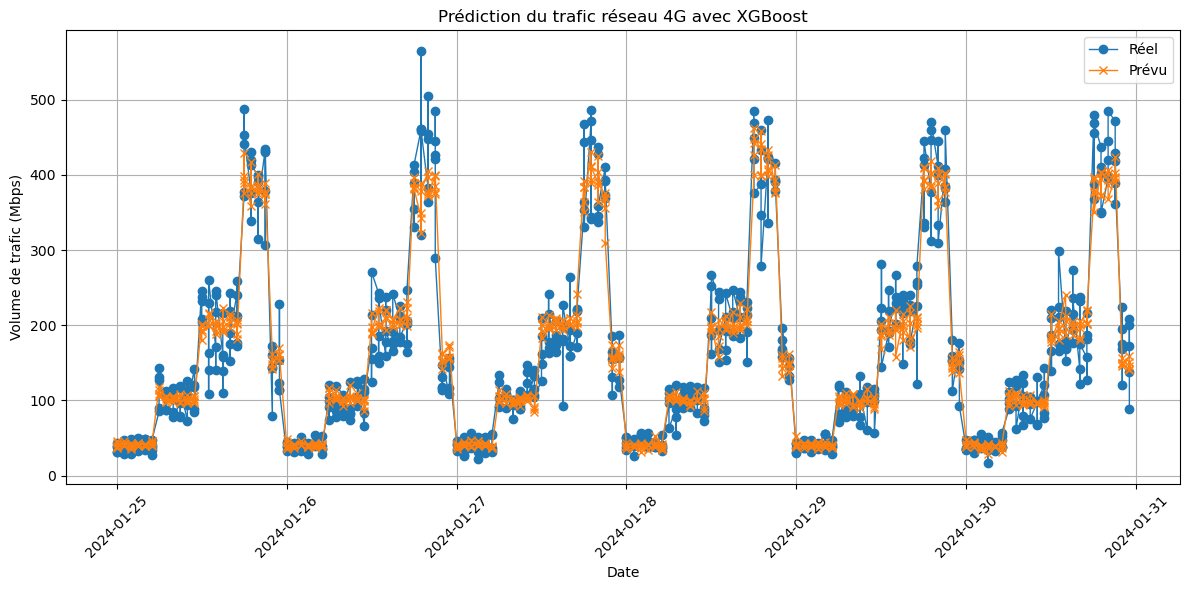

In [21]:
plt.figure(figsize=(12, 6))
plt.plot(ts_test.values, y_test.values, label='Réel', marker='o', linewidth=1)
plt.plot(ts_test.values, y_pred, label='Prévu', marker='x', linewidth=1)
plt.xlabel('Date')
plt.ylabel('Volume de trafic (Mbps)')
plt.title('Prédiction du trafic réseau 4G avec XGBoost')
plt.xticks(rotation=45)
plt.legend()
plt.tight_layout()
plt.grid(True)
plt.show()

In [23]:
df.shape

(3600, 12)